# Hillstrom Email Marketing: S-Learner

This notebook is Experiment 1 for the capstone. It estimates heterogeneous effects of **any promotional email** versus **no email** on a website visit. It uses only a single S-Learner; no other causal ML algorithm is implemented here.

The source is Kevin Hillstrom's [MineThatData E-Mail Analytics and Data Mining Challenge (2008)](https://blog.minethatdata.com/2008/03/minethatdata-e-mail-analytics-and-data.html). The original experiment randomly assigned customers to Men's E-Mail, Women's E-Mail, or No E-Mail. Pooling the two email arms defines the binary treatment for this first experiment. Therefore, estimates apply to the policy “send either campaign email” rather than a specific email creative.

`visit` is the primary binary outcome: a website visit during the two weeks after the campaign. `conversion` and `spend` are post-treatment outcomes and are deliberately excluded from features.


In [1]:
from pathlib import Path
import hashlib
import platform
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.metrics import auc
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder

RANDOM_SEED = 42
TEST_SIZE = 0.20
SOURCE_URL = "http://www.minethatdata.com/Kevin_Hillstrom_MineThatData_E-MailAnalytics_DataMiningChallenge_2008.03.20.csv"
EXPECTED_SHA256 = "0e5893329d8b93cefecc571777672028290ab69865718020c78c7284f291aece"
DATA_PATH = Path("../data/raw/Kevin_Hillstrom_MineThatData_E-MailAnalytics_DataMiningChallenge_2008.03.20.csv")

assert DATA_PATH.exists(), f"Missing data file: {DATA_PATH.resolve()}"
actual_sha256 = hashlib.sha256(DATA_PATH.read_bytes()).hexdigest()
assert actual_sha256 == EXPECTED_SHA256, "The local file checksum does not match the pinned source file."

print(f"Python: {platform.python_version()}")
print(f"pandas: {pd.__version__}; scikit-learn: {sklearn.__version__}")
print(f"Data file: {DATA_PATH.resolve()}")
print(f"SHA-256: {actual_sha256}")


Matplotlib is building the font cache; this may take a moment.


Python: 3.12.15
pandas: 3.1.1; scikit-learn: 1.9.1
Data file: /Users/vedantnileshshinde/Vedant/Developer/projects/causal-experiments/data/raw/Kevin_Hillstrom_MineThatData_E-MailAnalytics_DataMiningChallenge_2008.03.20.csv
SHA-256: 0e5893329d8b93cefecc571777672028290ab69865718020c78c7284f291aece


## A. Data validation and study design

Pretreatment covariates are recency, past-year spending and spending segment, past Men's/Women's purchases, ZIP category, new-customer flag, and purchase channel. The treatment assignment (`segment`) and the three two-week outcomes (`visit`, `conversion`, `spend`) are not covariates. The treatment indicator is 1 for either email arm and 0 for No E-Mail.


In [2]:
df = pd.read_csv(DATA_PATH)
print("Shape:", df.shape)
display(df.head())
print("\nData types:")
display(df.dtypes.to_frame("dtype"))
print("\nMissing values:")
display(df.isna().sum().to_frame("missing"))
print("Duplicate rows:", df.duplicated().sum())
print("\nOriginal randomized groups:")
display(df["segment"].value_counts().rename_axis("segment").to_frame("count"))
print("\nOutcome distributions:")
display(df[["visit", "conversion", "spend"]].agg(["count", "mean", "sum", "min", "max"]).T)


Shape: (64000, 12)


,recency,history_segment,history,mens,womens,zip_code,newbie,channel,segment,visit,conversion,spend
0,10,2) $100 - $200,142.44,1,0,Surburban,0,Phone,Womens E-Mail,0,0,0.0
1,6,3) $200 - $350,329.08,1,1,Rural,1,Web,No E-Mail,0,0,0.0
2,7,2) $100 - $200,180.65,0,1,Surburban,1,Web,Womens E-Mail,0,0,0.0
3,9,5) $500 - $750,675.83,1,0,Rural,1,Web,Mens E-Mail,0,0,0.0
4,2,1) $0 - $100,45.34,1,0,Urban,0,Web,Womens E-Mail,0,0,0.0



Data types:


,dtype
recency,int64
history_segment,str
history,float64
mens,int64
womens,int64
zip_code,str
newbie,int64
channel,str
segment,str
visit,int64



Missing values:


,missing
recency,0
history_segment,0
history,0
mens,0
womens,0
zip_code,0
newbie,0
channel,0
segment,0
visit,0


Duplicate rows: 6562

Original randomized groups:


,count
segment,
Womens E-Mail,21387
Mens E-Mail,21307
No E-Mail,21306



Outcome distributions:


,count,mean,sum,min,max
visit,64000.0,0.146781,9394.00,0.0,1.0
conversion,64000.0,0.009031,578.00,0.0,1.0
spend,64000.0,1.050908,67258.13,0.0,499.0


In [3]:
feature_cols = [
    "recency", "history_segment", "history", "mens", "womens",
    "zip_code", "newbie", "channel",
]
numeric_features = ["recency", "history", "mens", "womens", "newbie"]
categorical_features = ["history_segment", "zip_code", "channel"]

df["treatment"] = (df["segment"] != "No E-Mail").astype(int)
df["outcome"] = df["visit"].astype(int)

print("Binary treatment distribution (any email vs. no email):")
display(pd.crosstab(df["treatment"], columns="count", normalize=False))
print("\nVisit outcome distribution:")
display(df["outcome"].value_counts().rename_axis("visit").to_frame("count"))

# Standardized mean differences (SMDs) assess balance after pooling the email arms.
balance_x = pd.get_dummies(df[feature_cols], columns=categorical_features, dtype=float)
rows = []
for column in balance_x:
    treated = balance_x.loc[df.treatment == 1, column]
    control = balance_x.loc[df.treatment == 0, column]
    pooled_sd = np.sqrt((treated.var(ddof=1) + control.var(ddof=1)) / 2)
    smd = (treated.mean() - control.mean()) / pooled_sd if pooled_sd > 0 else 0.0
    rows.append([column, treated.mean(), control.mean(), smd])

balance = pd.DataFrame(rows, columns=["feature", "email_mean", "control_mean", "SMD"])
balance["abs_SMD"] = balance["SMD"].abs()
balance = balance.sort_values("abs_SMD", ascending=False)
display(balance.round(4))
print("Largest absolute SMD:", round(balance["abs_SMD"].max(), 4))
print("A common descriptive threshold is |SMD| < 0.10; randomization does not require every SMD to be zero.")


Binary treatment distribution (any email vs. no email):


col_0,count
treatment,
0,21306
1,42694



Visit outcome distribution:


,count
visit,
0,54606
1,9394


,feature,email_mean,control_mean,SMD,abs_SMD
6,history_segment_2) $100 - $200,0.2206,0.2270,-0.0153,0.0153
11,"history_segment_7) $1,000 +",0.0209,0.0195,0.0097,0.0097
12,zip_code_Rural,0.1505,0.1473,0.0088,0.0088
7,history_segment_3) $200 - $350,0.1931,0.1898,0.0084,0.0084
1,history,242.6860,240.8827,0.0071,0.0071
2,mens,0.5499,0.5532,-0.0066,0.0066
13,zip_code_Surburban,0.4486,0.4518,-0.0064,0.0064
3,womens,0.5508,0.5476,0.0063,0.0063
0,recency,5.7707,5.7497,0.0060,0.0060
5,history_segment_1) $0 - $100,0.3597,0.3573,0.0051,0.0051


Largest absolute SMD: 0.0153
A common descriptive threshold is |SMD| < 0.10; randomization does not require every SMD to be zero.


**Leakage and methodological checks.** All selected features are recorded before treatment. The treatment label is added only as the S-Learner intervention variable. `visit`, `conversion`, and `spend` occur after email assignment and are never used as predictors. Pooling Men's and Women's emails creates a meaningful “any email” policy contrast, but it also mixes two creatives; it does not estimate either creative's separate effect. There is no customer identifier in the source, so duplicate full records are only a limited data-quality check, not evidence about duplicate customers.


## B. Randomized experimental baseline

The next estimate is a **difference in observed visit rates** between randomly assigned groups. Because assignment was randomized, it is an experimental estimate of the average causal effect under the study design. It is not an observational association and it is not a model estimate. The 95% confidence interval uses an unpooled Wald standard error for two independent proportions.


In [4]:
def difference_in_means(y, treatment):
    y1 = y[treatment == 1]
    y0 = y[treatment == 0]
    p1, p0 = y1.mean(), y0.mean()
    effect = p1 - p0
    se = np.sqrt(p1 * (1 - p1) / len(y1) + p0 * (1 - p0) / len(y0))
    return pd.Series({
        "treated_n": len(y1), "control_n": len(y0),
        "treated_rate": p1, "control_rate": p0,
        "ATE_difference": effect, "standard_error": se,
        "CI_95_low": effect - 1.96 * se, "CI_95_high": effect + 1.96 * se,
    })

full_baseline = difference_in_means(df["outcome"], df["treatment"])
display(full_baseline.to_frame("full randomized sample").round(5))


,full randomized sample
treated_n,42694.00000
control_n,21306.00000
treated_rate,0.16705
control_rate,0.10617
ATE_difference,0.06088
standard_error,0.00278
CI_95_low,0.05544
CI_95_high,0.06633


## C. S-Learner setup

The fixed 80/20 split is stratified by treatment and outcome so both appear in train and test. The test set will not be used to tune the model, choose features, or select targeting thresholds. A random forest classifier is used as one flexible, readable outcome model with fixed parameters: 300 trees, depth 8, at least 100 samples per leaf, and seed 42. Imputation and one-hot encoding are fit on training data only.

The S-Learner fits one model for \(E[Y \mid X, T]\). For every test customer we predict \(\hat\mu_1(X)=\hat E[Y\mid X,T=1]\) and \(\hat\mu_0(X)=\hat E[Y\mid X,T=0]\); estimated CATE is \(\hat	au(X)=\hat\mu_1(X)-\hat\mu_0(X)\).


In [5]:
X = df[feature_cols].copy()
y = df["outcome"].copy()
t = df["treatment"].copy()
strata = t.astype(str) + "_" + y.astype(str)

X_train, X_test, y_train, y_test, t_train, t_test = train_test_split(
    X, y, t, test_size=TEST_SIZE, random_state=RANDOM_SEED, stratify=strata
)

print("Train rows:", len(X_train), "Test rows:", len(X_test))
display(pd.crosstab(t_train, y_train, normalize="index").round(4))

preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", Pipeline([("imputer", SimpleImputer(strategy="median"))]), numeric_features + ["treatment"]),
        ("categorical", Pipeline([
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("onehot", OneHotEncoder(handle_unknown="ignore")),
        ]), categorical_features),
    ]
)

model = Pipeline([
    ("preprocess", preprocessor),
    ("random_forest", RandomForestClassifier(
        n_estimators=300, max_depth=8, min_samples_leaf=100,
        random_state=RANDOM_SEED, n_jobs=-1,
    )),
])

X_train_model = X_train.copy()
X_train_model["treatment"] = t_train.to_numpy()
model.fit(X_train_model, y_train)
print(model.named_steps["random_forest"])


Train rows: 51200 Test rows: 12800


outcome,0,1
treatment,,
0,0.8938,0.1062
1,0.8329,0.1671


RandomForestClassifier(max_depth=8, min_samples_leaf=100, n_estimators=300,
                       n_jobs=-1, random_state=42)


In [6]:
def potential_outcomes(model, features):
    treated_features = features.copy()
    control_features = features.copy()
    treated_features["treatment"] = 1
    control_features["treatment"] = 0
    mu1 = model.predict_proba(treated_features)[:, 1]
    mu0 = model.predict_proba(control_features)[:, 1]
    return mu1, mu0

mu1_test, mu0_test = potential_outcomes(model, X_test)
cate_test = mu1_test - mu0_test

test_results = X_test.copy()
test_results["treatment"] = t_test.to_numpy()
test_results["outcome"] = y_test.to_numpy()
test_results["mu1"] = mu1_test
test_results["mu0"] = mu0_test
test_results["cate"] = cate_test

test_baseline = difference_in_means(test_results["outcome"], test_results["treatment"])
model_ate = cate_test.mean()
print(f"S-Learner mean estimated CATE on held-out test set: {model_ate:.5f}")
print(f"Held-out randomized ATE: {test_baseline['ATE_difference']:.5f} "
      f"(95% CI {test_baseline['CI_95_low']:.5f}, {test_baseline['CI_95_high']:.5f})")
display(pd.Series(cate_test).describe(percentiles=[0.01, 0.1, 0.25, 0.5, 0.75, 0.9, 0.99]).to_frame("estimated_CATE"))


S-Learner mean estimated CATE on held-out test set: 0.04726
Held-out randomized ATE: 0.06092 (95% CI 0.04875, 0.07309)


,estimated_CATE
count,12800.000000
mean,0.047258
std,0.015883
min,0.006101
1%,0.013750
10%,0.026295
25%,0.034687
50%,0.048457
75%,0.058432
90%,0.066992


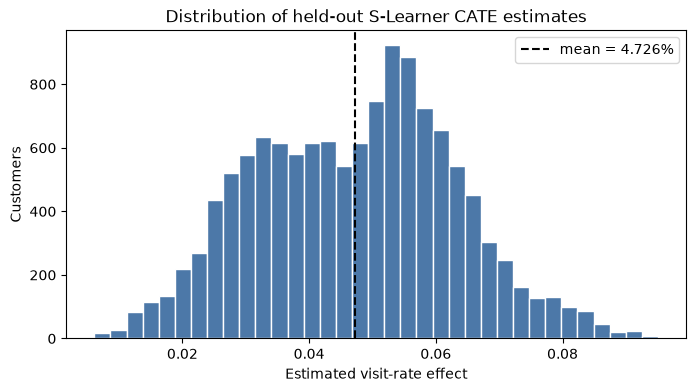

Estimated effects by recency quartile:


,customers,mean_cate,median_cate
recency_group,,,
"(0.999, 2.0]",3265,0.04953,0.05011
"(2.0, 5.0]",3171,0.04642,0.04821
"(5.0, 9.0]",3733,0.04651,0.04721
"(9.0, 12.0]",2631,0.04650,0.04803


Estimated effects by prior purchase channel:


,customers,mean_cate,median_cate
channel,,,
Web,5677,0.04793,0.04948
Multichannel,1508,0.04695,0.04710
Phone,5615,0.04666,0.04723


In [7]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(cate_test, bins=35, color="#4C78A8", edgecolor="white")
ax.axvline(model_ate, color="black", linestyle="--", label=f"mean = {model_ate:.3%}")
ax.set(title="Distribution of held-out S-Learner CATE estimates", xlabel="Estimated visit-rate effect", ylabel="Customers")
ax.legend()
plt.show()

segment_summary = (
    test_results.assign(recency_group=pd.qcut(test_results["recency"], q=4, duplicates="drop"))
    .groupby("recency_group", observed=True)
    .agg(customers=("cate", "size"), mean_cate=("cate", "mean"), median_cate=("cate", "median"))
)
print("Estimated effects by recency quartile:")
display(segment_summary.round(5))

channel_summary = (
    test_results.groupby("channel", observed=True)
    .agg(customers=("cate", "size"), mean_cate=("cate", "mean"), median_cate=("cate", "median"))
    .sort_values("mean_cate", ascending=False)
)
print("Estimated effects by prior purchase channel:")
display(channel_summary.round(5))


## D. Held-out uplift evaluation

Individual counterfactual visits are unobserved, so this notebook does not calculate ITE error. Instead, it ranks the untouched randomized test observations by predicted CATE. Within each ranking group, the difference in observed treatment and control visit rates estimates that group's realized uplift. The targeting budget is set **before** looking at test outcomes: the top 30% by predicted CATE.


,uplift_decile,n,treated_rate,control_rate,ATE_difference,CI_95_low,CI_95_high
0,1,1280,0.23002,0.13436,0.09566,0.05314,0.13818
1,2,1280,0.18699,0.10979,0.07721,0.03753,0.11688
2,3,1280,0.16468,0.09502,0.06966,0.03253,0.10678
3,4,1280,0.17396,0.08495,0.08901,0.05212,0.12590
4,5,1280,0.17163,0.11565,0.05599,0.01672,0.09525
5,6,1280,0.18558,0.12442,0.06116,0.02053,0.10178
6,7,1280,0.14422,0.09977,0.04445,0.00774,0.08115
7,8,1280,0.11908,0.09157,0.02751,-0.00765,0.06266
8,9,1280,0.13766,0.07980,0.05786,0.02289,0.09282
9,10,1280,0.15945,0.12189,0.03756,-0.00255,0.07768


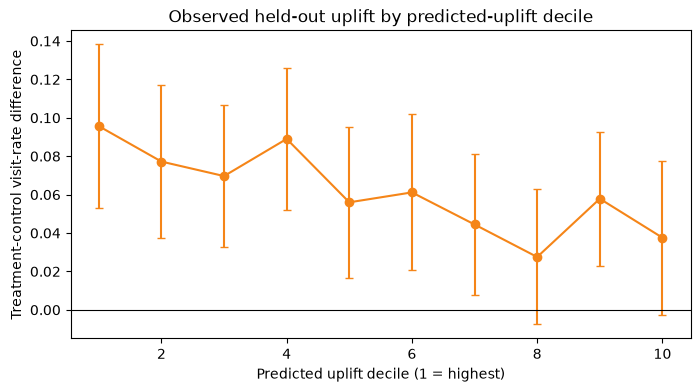

In [8]:
def grouped_observed_effect(data, group_column):
    rows = []
    for group, part in data.groupby(group_column, observed=True):
        estimate = difference_in_means(part["outcome"], part["treatment"])
        rows.append({"group": group, "n": len(part), **estimate.to_dict()})
    return pd.DataFrame(rows)

test_results["uplift_decile"] = pd.qcut(
    test_results["cate"].rank(method="first", ascending=False), q=10, labels=range(1, 11)
)
decile_effects = grouped_observed_effect(test_results, "uplift_decile")
decile_effects["uplift_decile"] = decile_effects["group"].astype(int)
decile_effects = decile_effects.sort_values("uplift_decile")
display(decile_effects[["uplift_decile", "n", "treated_rate", "control_rate", "ATE_difference", "CI_95_low", "CI_95_high"]].round(5))

fig, ax = plt.subplots(figsize=(8, 4))
ax.errorbar(
    decile_effects["uplift_decile"], decile_effects["ATE_difference"],
    yerr=[decile_effects["ATE_difference"] - decile_effects["CI_95_low"],
          decile_effects["CI_95_high"] - decile_effects["ATE_difference"]],
    fmt="o-", capsize=3, color="#F58518",
)
ax.axhline(0, color="black", linewidth=0.8)
ax.set(title="Observed held-out uplift by predicted-uplift decile", xlabel="Predicted uplift decile (1 = highest)", ylabel="Treatment-control visit-rate difference")
plt.show()


AUUC (incremental visits across fractions): 456.384
Qini coefficient (area above its random line): 42.185


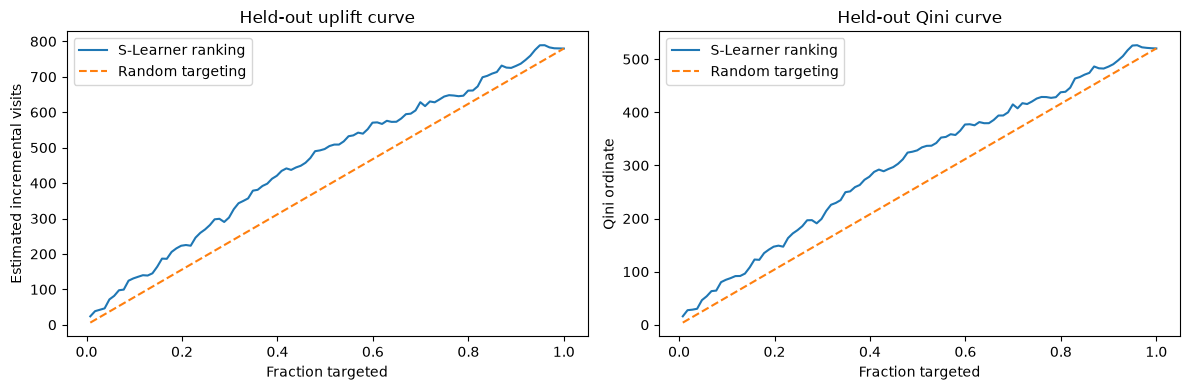

In [9]:
def uplift_curves(data, n_points=100):
    ordered = data.sort_values("cate", ascending=False).reset_index(drop=True)
    rows = []
    for k in np.unique(np.linspace(100, len(ordered), n_points, dtype=int)):
        part = ordered.iloc[:k]
        n_treated = (part.treatment == 1).sum()
        n_control = (part.treatment == 0).sum()
        if n_treated == 0 or n_control == 0:
            continue
        treatment_effect = part.loc[part.treatment == 1, "outcome"].mean() - part.loc[part.treatment == 0, "outcome"].mean()
        # Expected incremental visits if every customer in this prefix were targeted.
        uplift_gain = k * treatment_effect
        # Standard Qini ordinate: treated responders minus reweighted control responders.
        qini = part.loc[part.treatment == 1, "outcome"].sum() - (n_treated / n_control) * part.loc[part.treatment == 0, "outcome"].sum()
        rows.append([k, k / len(ordered), uplift_gain, qini])
    curves = pd.DataFrame(rows, columns=["n_targeted", "population_fraction", "uplift_gain", "qini"])
    random_uplift = len(ordered) * test_baseline["ATE_difference"] * curves["population_fraction"]
    random_qini = curves["qini"].iloc[-1] * curves["population_fraction"]
    auuc = auc(curves["population_fraction"], curves["uplift_gain"])
    qini_coefficient = auc(curves["population_fraction"], curves["qini"] - random_qini)
    return curves, random_uplift, random_qini, auuc, qini_coefficient

curves, random_uplift, random_qini, auuc, qini_coefficient = uplift_curves(test_results)
print(f"AUUC (incremental visits across fractions): {auuc:.3f}")
print(f"Qini coefficient (area above its random line): {qini_coefficient:.3f}")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(curves["population_fraction"], curves["uplift_gain"], label="S-Learner ranking")
axes[0].plot(curves["population_fraction"], random_uplift, "--", label="Random targeting")
axes[0].set(title="Held-out uplift curve", xlabel="Fraction targeted", ylabel="Estimated incremental visits")
axes[0].legend()
axes[1].plot(curves["population_fraction"], curves["qini"], label="S-Learner ranking")
axes[1].plot(curves["population_fraction"], random_qini, "--", label="Random targeting")
axes[1].set(title="Held-out Qini curve", xlabel="Fraction targeted", ylabel="Qini ordinate")
axes[1].legend()
plt.tight_layout()
plt.show()


In [10]:
TARGET_FRACTION = 0.30
cutoff_rank = int(np.ceil(TARGET_FRACTION * len(test_results)))
top_target = test_results.nlargest(cutoff_rank, "cate")
top_effect = difference_in_means(top_target["outcome"], top_target["treatment"])

targeting_comparison = pd.DataFrame([
    {
        "strategy": "Target everyone",
        "customers_targeted": len(test_results),
        "observed_uplift": test_baseline["ATE_difference"],
        "CI_95_low": test_baseline["CI_95_low"],
        "CI_95_high": test_baseline["CI_95_high"],
    },
    {
        "strategy": "Random 30% (expected)",
        "customers_targeted": cutoff_rank,
        "observed_uplift": test_baseline["ATE_difference"],
        "CI_95_low": test_baseline["CI_95_low"],
        "CI_95_high": test_baseline["CI_95_high"],
    },
    {
        "strategy": "Top predicted 30%",
        "customers_targeted": cutoff_rank,
        "observed_uplift": top_effect["ATE_difference"],
        "CI_95_low": top_effect["CI_95_low"],
        "CI_95_high": top_effect["CI_95_high"],
    },
])
targeting_comparison["estimated_incremental_visits"] = (
    targeting_comparison["customers_targeted"] * targeting_comparison["observed_uplift"]
)
targeting_comparison["incremental_visits_CI_low"] = targeting_comparison["customers_targeted"] * targeting_comparison["CI_95_low"]
targeting_comparison["incremental_visits_CI_high"] = targeting_comparison["customers_targeted"] * targeting_comparison["CI_95_high"]
display(targeting_comparison.round(4))


,strategy,customers_targeted,observed_uplift,CI_95_low,CI_95_high,estimated_incremental_visits,incremental_visits_CI_low,incremental_visits_CI_high
0,Target everyone,12800,0.0609,0.0488,0.0731,779.7772,624.0183,935.5360
1,Random 30% (expected),3840,0.0609,0.0488,0.0731,233.9332,187.2055,280.6608
2,Top predicted 30%,3840,0.0804,0.0573,0.1034,308.5647,220.0703,397.0590


## E. Findings to carry into the capstone

Use the executed tables and figures above as the numerical record for Methods and Results. The full-data baseline is the randomized experiment's overall ATE; the held-out baseline, decile table, curves, and targeting comparison are evaluation outputs. The S-Learner's average predicted CATE is a model-based estimate and should not be described as a directly observed effect.

Limitations:

- The dataset supports randomized average and subgroup comparisons, but never reveals both potential visits for a person; individual-level CATE accuracy cannot be verified.
- Pooling the two email creatives estimates an “any email” policy, possibly masking creative-specific heterogeneity.
- Uplift curves and the top-30% comparison use one held-out split, so subgroup estimates can be noisy and should not be treated as deployment-ready proof.
- The 30% budget is a prespecified illustrative business constraint; a real deployment needs campaign cost, capacity, and repeat-experiment evidence.
- Results generalize only to these prior customers and this two-week outcome window.
